<a href="https://colab.research.google.com/github/sara-velmont/Proyectos/blob/main/Proyecto_Bayes_Voces.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Modelos jerárquicos con predictores**
###Estadística Bayesiana
####Por: Sara Nayely Vélez Montesinos

**Ejercicio 17.10 (Voces: planteando el modelo)** \\
¿Cambia el tono de voz de una persona dependiendo de su actitud? Para abordar esta pregunta, Winter y Grawunder (2012) realizaron un estudio en el que cada sujeto participó en varios diálogos de rol. Estos diálogos abarcaban diferentes contextos (por ejemplo, pedir un favor) y se abordaban con diferentes actitudes (cortés vs informal).
En los siguientes ejercicios explorarás un análisis de regresión jerárquica de $Y_{ij}$, el tono de voz promedio en la i-ésima sesión de diálogo del sujeto j (medido en Hz), en función de $X_{ij}$, que indica si el diálogo fue cortés (vs informal).
Más allá de entender que el tono de voz típico es de alrededor de 200 Hz, deberás utilizar priors débilmente informativos. \\


1.   Utilizando notación formal, define el modelo de regresión jerárquica de $Y_{ij}$ en función de $X_{ij}$. Al hacerlo, asume que el tono de voz base varía de un sujeto a otro, pero que el impacto de la actitud sobre el tono de voz es similar entre todos los sujetos.

2.   Compara y contrasta los significados de los parámetros del modelo $β_{0j}$
y $β_0$ en el contexto de este estudio sobre tono de voz.
\\NOTA: Recuerda que $X_{ij}$ es una variable indicadora categórica.

3. Compara y contrasta los significados de los parámetros del modelo $σ_y$ y $σ_0$ en el contexto de este estudio sobre tono de voz.




Respuesta (1): \\
$Y_{ij}$: Valor esperado del diálogo en Hz. \\
Predictores: $X_{ij}=$
\begin{array}{ll}
0 & \text{si el diálogo es informal} \\
1 & \text{si el diálogo es cortés}
\end{array}


 El tono de voz base varía de un sujeto a otro (modelo jerárquico) podemos decir que:
\begin{equation}
Y_{ij}|β_{0j},β_1,σ_y∼ N(\mu_{ij},\sigma_y^2)
\end{equation}
Donde
\begin{equation}
\mu_{ij}=β_{0j}+β_1 X_{ij}
\end{equation}
y \\
* $\beta_{0j}$: Intercepto correspondiente a la persona j \\
* $\beta_1$: Coeficiente de cambio en la actitud \\
* $σ_y$: Desviación estándar (variabilidad dentro del grupo alrededor del modelo de regresión media $\mu_{ij}$)

El problema menciona que "el impacto de la actitud sobre el tono de voz es similar entre todos los sujetos" entonces $\beta_1$ debe ser un efecto común para todos los sujetos. \\
Los interceptos comparten una distribución a priori:
\begin{equation}
\beta_{0j}|\beta_0,\sigma_0 ∼ N(\beta_0,\sigma_0^2)
\end{equation}
* $\beta_0$: Media general del intercepto (nivel base promedio en la población)
* $\sigma_0$: Variabilidad entre sujetos en su diálogo informal

Se deben especificar priors para $\beta_0$, $\beta_1$, $\sigma_y$ y $\sigma_0$, donde nuestra comprensión previa de $\beta_0$ se expresa a través de $\beta_{0c}$:
\begin{array}{ll}
\beta_{0c} &∼ N(m_0,s_0^2) \\
\beta_1 &∼ N(m_1,s_1^2)\\
\sigma_y &∼ Exp(l_y) \\
\sigma_0 &∼ Exp(l_0) \\
\end{array}

Donde $m_0$, $m_1$, $s_0$, $s_1$, $l_y$ y $l_0$ son variables a definir según sea conveniente para este problema.
Ya que las distribuciones apriori (priors) deber ser débilmente informativas, según indica el problema podemos proponer:
\begin{array}{ll}
\beta_{0c} &∼ N(200,50^2) \\
\beta_1 &∼ N(0,50^2)\\
\sigma_y &∼ Exp(1) \\
\sigma_0 &∼ Exp(1) \\
\end{array}
Aquí para $\beta_{0c}$ se consideró que el tono de voz típico es de alrededor de 200 Hz, para $\beta_1$ se espera un efecto pero no se sabe el tamaño ni la dirección. Para las desviaciones estándar se ha escogido un valor típico al rededor de 1, se favorecen valores pequeños pero deja la puerta abierta a valores grandes.






Respuesta (2): \\
**$\beta_0$:** Es la media general del intercepto (nivel base promedio en la población). Es decir el tono promedio entre todos los sujetos, en este caso es de 200 Hz. Donde nuestra comprensión previa de la línea base se expresa a través del intercepto centrado $\beta_{0c}$. Es decir se espera a priori que para cada individuo, su tono base informal esté dentro de los valores de esta distribución cuyo centro son 200 Hz y la medida de dispersión son 30 Hz al rededor de este valor. \\
**$\beta_{0j}$**: Es el intercepto específico del sujeto j. Cada individuo tiene su propia distribución a priori, además brinda información compartida entre ellos ya que comparten la misma distribución. Es decir, todos los sujetos tienen un tono informal que se distribuye normal, para cada uno $\beta_0$ y $\sigma_0$ tienen un propio valor que cae dentro de los priors de estos parámetros. \\
Cuando el predictor $X_{ij}=0$, el término $\beta_1X_{ij}$ se cancela y tenemos que:
\begin{equation}
Y_{ij}=\beta_{0j}+ϵ_{ij}
\end{equation}
Es decir, el valor esperado del discurso para ese sujeto depende solamente de su intercepto $\beta_{0j}$ cuando la actitud es informal.



Respuesta (3): \\
$\sigma_0$: Representa la variabilidad entre los individuos, esto es el grado en que el tono informal varía de un sujeto a otro. \\
$\sigma_y$: Mide variabilidad del discurso de un mismo sujeto dado su actitud, es el grado en que las frecuencias de un sujeto podrían fluctuar.

Cargando paqueterías de R:

In [ ]:
!apt-get install -y r-base

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
r-base is already the newest version (4.5.0-2.2204.0).
0 upgraded, 0 newly installed, 0 to remove and 34 not upgraded.


In [ ]:
!pip install -q rpy2

In [ ]:
%load_ext rpy2.ipython


In [ ]:
%%R
install.packages("rstanarm", repos = "https://cloud.r-project.org")


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)
also installing the dependencies ‘rbibutils’, ‘lazyeval’, ‘plyr’, ‘Rdpack’, ‘numDeriv’, ‘crosstalk’, ‘zoo’, ‘litedown’, ‘igraph’, ‘ggridges’, ‘reshape2’, ‘minqa’, ‘nloptr’, ‘reformulas’, ‘checkmate’, ‘matrixStats’, ‘abind’, ‘tensorA’, ‘distributional’, ‘inline’, ‘gridExtra’, ‘QuickJSR’, ‘colourpicker’, ‘DT’, ‘dygraphs’, ‘gtools’, ‘markdown’, ‘shinyjs’, ‘shinythemes’, ‘threejs’, ‘xts’, ‘bayesplot’, ‘lme4’, ‘loo’, ‘posterior’, ‘rstan’, ‘rstantools’, ‘shinystan’, ‘RcppParallel’, ‘StanHeaders’, ‘BH’, ‘RcppEigen’

trying URL 'https://cloud.r-project.org/src/contrib/rbibutils_2.3.tar.gz'
trying URL 'https://cloud.r-project.org/src/contrib/lazyeval_0.2.2.tar.gz'
trying URL 'https://cloud.r-project.org/src/contrib/plyr_1.8.9.tar.gz'
trying URL 'https://cloud.r-project.org/src/contrib/Rdpack_2.6.4.tar.gz'
trying URL 'https://cloud.r-project.org/src/contrib/numDeriv_2016.8-1.1.tar.gz'
trying URL 'https://cloud.r-pr

**Ejercicio 17.11 (Voces: explorando los datos)** \\
Para equilibrar nuestros priors débilmente informativos en el modelo del tono de voz según la actitud, examinemos algunos datos.

Carga los datos de voices del paquete bayesrules. \\
¿Cuántos sujetos participaron en este estudio? \
¿En cuántos diálogos participó cada sujeto?

Construye y analiza una gráfica que ilustre la relación entre el tono de voz y la actitud, tanto dentro de cada sujeto como entre distintos sujetos.

Cargando datos...

In [ ]:
%%R
# Install the bayesrules package
if (!require("bayesrules")) install.packages("bayesrules")

# Load the bayesrules package
library(bayesrules)

# Load the voices dataset
data("voices", package = "bayesrules")

head(voices)

# A tibble: 6 × 4
  subject scenario attitude pitch
  <fct>   <fct>    <fct>    <dbl>
1 A       A        polite    230.
2 A       A        informal  237.
3 A       B        polite    237.
4 A       B        informal  251 
5 A       C        polite    267 
6 A       C        informal  266 


Loading required package: bayesrules
Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)
also installing the dependencies ‘snakecase’, ‘proxy’, ‘numbers’, ‘rearrr’, ‘janitor’, ‘e1071’, ‘groupdata2’

trying URL 'https://cran.rstudio.com/src/contrib/snakecase_0.11.1.tar.gz'
trying URL 'https://cran.rstudio.com/src/contrib/proxy_0.4-27.tar.gz'
trying URL 'https://cran.rstudio.com/src/contrib/numbers_0.8-5.tar.gz'
trying URL 'https://cran.rstudio.com/src/contrib/rearrr_0.3.5.tar.gz'
trying URL 'https://cran.rstudio.com/src/contrib/janitor_2.2.1.tar.gz'
trying URL 'https://cran.rstudio.com/src/contrib/e1071_1.7-16.tar.gz'
trying URL 'https://cran.rstudio.com/src/contrib/groupdata2_2.0.5.tar.gz'
trying URL 'https://cran.rstudio.com/src/contrib/bayesrules_0.0.2.tar.gz'

The downloaded source packages are in
	‘/tmp/RtmpMINOSU/downloaded_packages’
In addition: Warning messages:
1: In library(package, lib.loc = lib.loc, character.only = TRUE, logical.return = TRUE, 

Sujetos que participaron en el estudio: 6

In [ ]:
%%R
# Número de sujetos únicos
length(unique(voices$subject))


[1] 6


In [ ]:
%%R
dplyr::n_distinct(voices$subject)


[1] 6


Diálogo por sujeto: 14 cada uno

In [ ]:
%%R
library(dplyr)

voices %>%
  count(subject) %>%
  rename("sujeto" = subject, "n_dialógos" = n)


# A tibble: 6 × 2
  sujeto n_dialógos
  <fct>       <int>
1 A              14
2 B              14
3 C              14
4 D              14
5 E              14
6 F              14



Attaching package: ‘dplyr’

The following objects are masked from ‘package:stats’:

    filter, lag

The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Gráfico para comparar el tono de voz y la actitud de cada sujeto y entre todos ellos.


(`geom_point()`). 



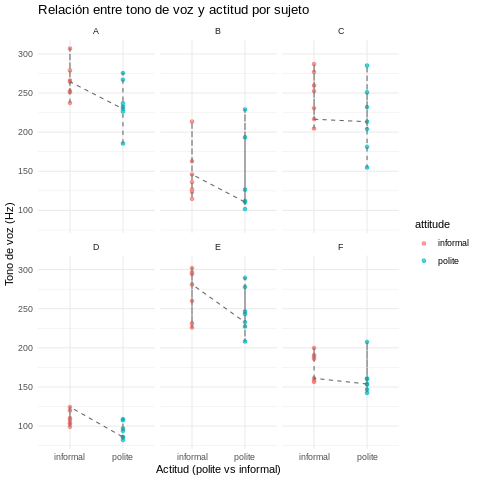

In [ ]:
%%R
library(ggplot2)
ggplot(voices, aes(x = attitude, y = pitch, color = attitude)) +
  geom_point(alpha = 0.7) +
  geom_line(aes(group = subject), color = "gray40", linetype = "dashed") +
  facet_wrap(~ subject) +
  theme_minimal() +
  labs(title = "Relación entre tono de voz y actitud por sujeto",
       y = "Tono de voz (Hz)",
       x = "Actitud (polite vs informal)")


Fila removida al parecer no se registró la información del tono de voz del participante B y por eso el programa la eliminó

In [ ]:
%%R
summary(voices)
anyNA(voices)
voices[!complete.cases(voices), ]

# A tibble: 1 × 4
  subject scenario attitude pitch
  <fct>   <fct>    <fct>    <dbl>
1 B       F        polite      NA


In [ ]:
%%R
# Tabla con promedio de pitch por sujeto y actitud
resumen_pitch <- voices %>%
  group_by(subject, attitude) %>%
  summarise(pitch_promedio = mean(pitch, na.rm = TRUE)) %>%
  arrange(subject, attitude)


print(resumen_pitch)

`summarise()` has grouped output by 'subject'. You can override using the
`.groups` argument.
# A tibble: 12 × 3
# Groups:   subject [6]
   subject attitude pitch_promedio
   <fct>   <fct>             <dbl>
 1 A       informal          265. 
 2 A       polite            236. 
 3 B       informal          146. 
 4 B       polite            146. 
 5 C       informal          247. 
 6 C       polite            217. 
 7 D       informal          110. 
 8 D       polite             94.5
 9 E       informal          270. 
10 E       polite            246. 
11 F       informal          177. 
12 F       polite            161. 


Análisis de gráfica:
Podemos encontrar variaciones en los tonos de cada sujeto dentro de la misma actitud, es decir individualmente la entonación de los discursos, ya sea formales o informales, podían variar en la mayoría de los casos más de 50 Hz, en algunos hasta 100 Hz. También podemos observar a partir de la línea punteada que une a las actitudes que la mayoría de ellos, tiende a bajar su entonación cuando adquiere una actitud formal. También se puede apreciar como cada sujeto tiene un rango de voz distinto, algunas más agudas que otras.

**Ejercicio 17.12 (Voces: simulando el modelo)**
Continuando con el análisis del tono de voz, en este ejercicio simularás y examinarás el posterior jerárquico de los parámetros de tu modelo.

Simula el modelo posterior jerárquico del tono de voz en función de la actitud. Construye y analiza gráficos de trace (trayectorias de la cadena), gráficos de densidad, gráficos de autocorrelación y un pp_check() (posterior predictive check) del resultado de la cadena.

Construye e interpreta un intervalo creíble del 95% para $\beta_0$. \\
Construye e interpreta un intervalo creíble del 95% para $\beta_1$. \\
¿Existe evidencia suficiente de que, en promedio, el tono de voz varía según la actitud (cortés vs informal)? \\
Explica.



In [ ]:
%%R
library(bayesplot)
library(tidyverse)

# attitude es una variable binaria (0 = informal, 1 = polite)
voices <- voices %>%
  mutate(attitude_bin = ifelse(attitude == "polite", 1, 0))

# Modelo jerárquico
modelo_voz <- stan_glmer(
  pitch ~ attitude_bin + (1 | subject),
  data = voices,
  family = gaussian(),
  prior_intercept = normal(200, 50),
  prior = normal(0, 20),
  prior_aux = exponential(1),
  chains = 4,
  iter = 4000,
  seed = 1234
)


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ lubridate 1.9.4     ✔ tibble    3.2.1
✔ purrr     1.0.4     ✔ tidyr     1.3.1
✔ readr     2.1.5     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


This is bayesplot version 1.12.0
- Online documentation and vignettes at mc-stan.org/bayesplot
- bayesplot theme set to bayesplot::theme_default()
   * Does _not_ affect other ggplot2 plots
   * See ?bayesplot_theme_set for details on theme setting


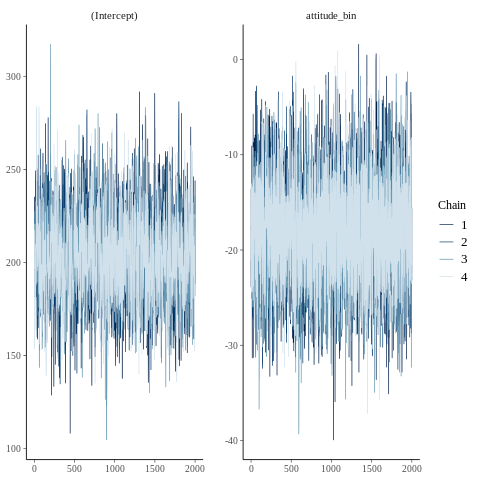

In [ ]:
%%R

# Trace plots (trayectorias)
mcmc_trace(as.array(modelo_voz), pars = c("(Intercept)", "attitude_bin"))



Se observa un buen comportamiento de las cadenas. Las cadenas se mezclan bien entre sí, es decir, no hay una que esté muy separada de las demás.

No hay tendencias visibles, las cadenas no están subiendo o bajando constantemente.

Los valores están bien distribuidos alrededor de una zona central, indicando estabilidad y convergencia.

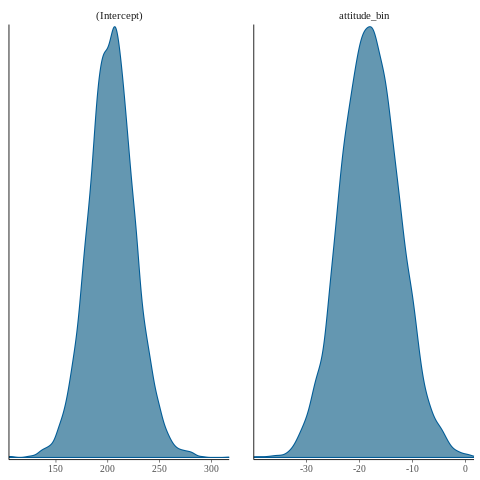

In [ ]:
%%R
# Densidad
mcmc_dens(as.array(modelo_voz), pars = c("(Intercept)", "attitude_bin"))


Para cada parámetro, vemos la distribución posterior basada en todas las iteraciones de las cadenas de Markov, ambas distribuciones están centradas.
Vemos cómo el intercepto sigue centrado al rededor de los 200 Hz, aunque se muestra que los valores már probables son un poco mayores. Se observa que los valores se dispersan entre +/- 50 Hz y valores menores o mayores son muy poco probables.

Podemos observar que la distribución para el parámetro $\beta_1$ está centrado en un valor negativo, sugiere que en promedio el tono de voz es más bajo cuando la actitud es cortés. El valor esperado está aproximadamente en -25 Hz, esto quiere decir que en promedio una persona bajará su tono de voz 25 Hz en un diálogo formal.

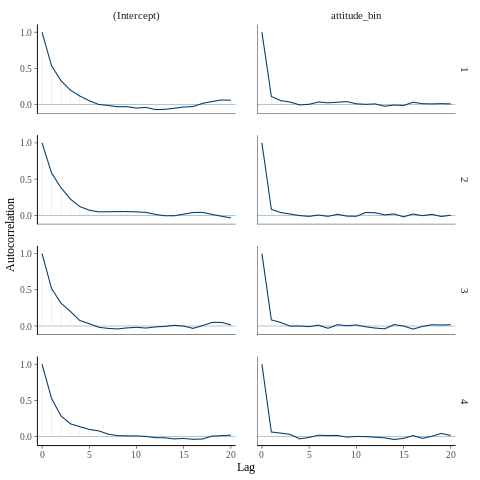

In [ ]:
%%R
# Autocorrelación
mcmc_acf(as.array(modelo_voz), pars = c("(Intercept)", "attitude_bin"))

La autocorrelación mide cuán correlacionadas están las muestras de las cadenas MCMC entre sí a lo largo de las iteraciones. Observamos para ambos parámetros y para todas las cadenas que la autocorrelación es baja, esto significa que las muestras son más independientes, lo cual es una señal de que las cadenas han convergido bien. También que sea baja indica que la cadena ha explorado bien el espacio de parámetros y que las iteraciones son suficientes.

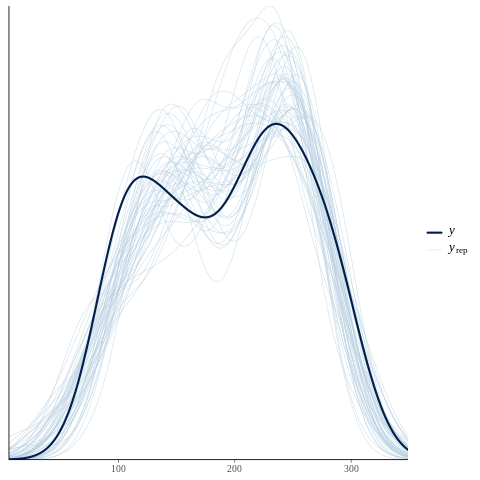

In [ ]:
%%R
# Chequeo predictivo posterior
pp_check(modelo_voz)

En esta curva podemos ver que se compara la distribución de los datos observados (y) con los datos simulados por el modelo (y_rep), es decir, una verificación predictiva posterior (posterior predictive check ppcheck).

Las curvas claras o sombreados son simulaciones de datos que el modelo ha generado, dados los parámetros ajustados. Podemos observar que las simulaciones se parecen mucho a los datos reales, esto significa que el modelo está generando datos plausibles, lo cual es una buena señal.

In [ ]:
%%R
posterior_summary <- posterior_interval(modelo_voz, prob = 0.95)
posterior_summary[c("(Intercept)", "attitude_bin"), ]


                  2.5%      97.5%
(Intercept)  159.95497 249.246266
attitude_bin -28.63026  -6.950158


Ya que el parámetro $\beta_1$ excluye el 0, esto quiere decir que sí hay evidencia de que el tono cambia entre actitudes.

**Ejercicio 17.13 (Voces: enfocándonos en el individuo)** \\
Continuando con el análisis del tono de voz, en este ejercicio te centrarás en sujetos específicos.

Informa la mediana posterior global del modelo que relaciona el tono de voz con la actitud. \\
Informa y contrasta las medianas posteriores de los modelos para dos sujetos de nuestros datos: A y F. \\
Usando posterior_predict(), simula modelos predictivos posteriores del tono de voz en un nuevo diálogo cortés para tres sujetos distintos: A, F y tú.
Ilustra los resultados de tu simulación usando mcmc_areas() y comenta tus hallazgos.

Mediana posterior global del modelo que relaciona el tono de voz con la actitud

In [ ]:
%%R
library(rstanarm)


posterior <- as.data.frame(summary(modelo_voz, probs = c(0.025, 0.5, 0.975)))

posterior[c("(Intercept)", "attitude_bin"), "50%"]


[1] 203.76849 -18.03398


Medianas posteriores de los modelos para dos sujetos de nuestros datos: A y F

In [ ]:
%%R
library(dplyr)

# Extrae nombres de sujetos
levels(voices$subject)

# Extrae muestras del modelo
post <- as.data.frame(modelo_voz) # Changed 'modelo_voices' to 'modelo_voz'

# Busca columnas de efectos aleatorios para sujetos A y F
mediana_A <- median(post[["b[(Intercept) subject:A]"]] + post[["attitude_bin"]])
mediana_F <- median(post[["b[(Intercept) subject:F]"]] + post[["attitude_bin"]])

mediana_A



[1] 37.17865


In [ ]:
%%R
mediana_F

[1] -43.34316


Para la última parte: Simular modelos predictivos posteriores del tono de voz en un nuevo diálogo cortés para tres sujetos distintos: A, F y yo. E ilustra los resultados de tu simulación usando mcmc_areas() se utilizó el siguiente código en R no ejecutado en Colab.

In [ ]:
nuevos_datos <- data.frame(
  subject = c("A", "F", "Z"),  # Z es un sujeto nuevo
  scenario = factor(rep("nuevo", 3), levels = levels(voices$scenario)),
  attitude = factor(rep("polite", 3), levels = levels(voices$attitude)),
  attitude_bin = ifelse(rep("polite", 3) == "polite", 1, 0)  # Corrected here
)

# Simula predicciones posteriores
# Changed 'modelo_voices' to 'modelo_voz' to match the model object name
simulaciones <- posterior_predict(modelo_voz, newdata = nuevos_datos)

# Visualiza con mcmc_areas
library(bayesplot)

mcmc_areas(
  as.matrix(simulaciones),
  prob = 0.95,
  pars = c("1", "2", "3")
) +
  ggtitle("Pitch simulado para un diálogo cortés") +
  scale_y_discrete(labels = c("A", "F", "Tú"))

El error que se presenta es específico del entorno de R en Colab.
Aunque el código sea correcto, Colab puede estar interpretando mal los factores. El código funciona en RStudio y reproduce el siguiente gráfico:


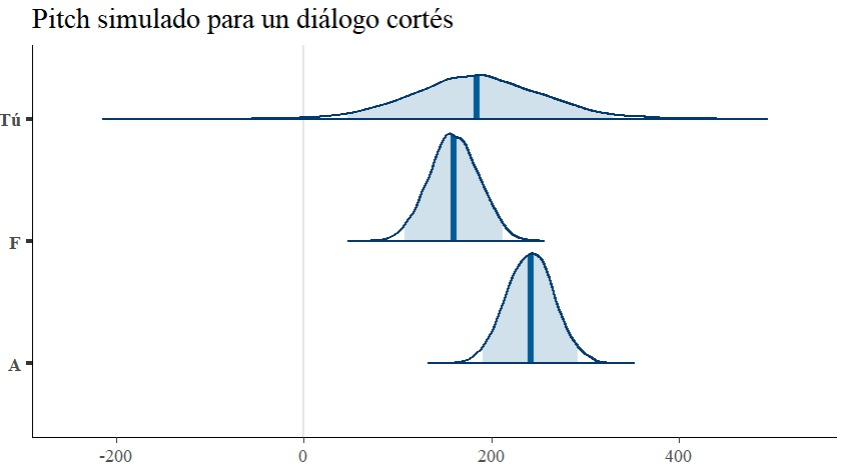

Cada curva azul es una distribución posterior de predicciones del pitch para el sujeto correspondiente en un escenario de diálogo cortés.

La línea vertical azul marca la mediana posterior.

La sombra azul claro representa el intervalo creíble del 95%: el rango donde el modelo cree que es más probable que esté el pitch.

A y F son sujetos del conjunto de datos original, por lo que el modelo puede ajustar efectos aleatorios específicos para ellos. Por eso sus curvas son más centradas y estrechas lo que representa mayor certeza.

Para el sujeto nuevo Z, como el modelo no tiene datos previos sobre él, la predicción se basa sólo en los efectos fijos, lo que da una distribución más ancha reflejando mayor incertidumbre. Esto se observa con una mayor dispersión,
centro de la curva más alto que posiblemente sea cercano a la media poblacional.